# Image extraction experiments

Use the reusable image extraction methods from scripts/3_images.py to inspect PDF image placements, sample extracted assets, and detect images spanning adjacent pages.

In [1]:
import importlib,sys
from pathlib import Path
import pandas as pd
from IPython.display import Image,display
cwd=Path.cwd().resolve(); candidates=[cwd,*cwd.parents,cwd/"SheCraft"/"ai-service",cwd/"ai-service"]
PROJECT_ROOT=next((x for x in candidates if (x/"src"/"rag"/"scripts").is_dir() and (x/"rag_documents").is_dir()),None)
if PROJECT_ROOT is None: raise RuntimeError("Could not locate ai-service project root.")
RAG_SRC_DIR=PROJECT_ROOT/"src"/"rag"
if str(RAG_SRC_DIR) not in sys.path: sys.path.insert(0,str(RAG_SRC_DIR))
DOCUMENTS_DIR=PROJECT_ROOT/"rag_documents"
ARTIFACT_ROOT=PROJECT_ROOT/"data"/"rag"/"processed_documents"
OUTPUT_DIR=PROJECT_ROOT/"data"/"rag"/"experiments"/"image_experiments"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PDF_FILES=sorted(DOCUMENTS_DIR.rglob("*.pdf"))
print("PDFs:",len(PDF_FILES))

PDFs: 39


# 2. Import helpers


In [2]:
images_module = importlib.reload(importlib.import_module("scripts.3_images"))
inspect_document_image_placements = images_module.inspect_document_image_placements
find_split_image_placements = images_module.find_split_image_placements
extract_document_images = images_module.extract_document_images
inspect_page_images = images_module.inspect_page_images
extract_pdf_image = images_module.extract_embedded_image
render_pdf_page = images_module.render_pdf_page
print("Imported reusable image extraction methods.")

Imported reusable image extraction methods.


# 3. Inspect images in jewelry PDFs


## 3.1 Inventory raster images across all pages


In [3]:
document_image_inspections = [
    inspect_document_image_placements(pdf_file)
    for pdf_file in PDF_FILES
]
image_inventory_rows = []
for document in document_image_inspections:
    per_page = {}
    for placement in document["placements"]:
        row = per_page.setdefault(placement["page_number"], {
            "file_name": document["file_name"],
            "source_path": document["source_path"],
            "page_number": placement["page_number"],
            "image_count": 0,
            "extractable_images": 0,
        })
        row["image_count"] += 1
        row["extractable_images"] += int(placement["xref"] > 0)
    for page_number in range(1, document["page_count"] + 1):
        image_inventory_rows.append(per_page.get(page_number, {
            "file_name": document["file_name"],
            "source_path": document["source_path"],
            "page_number": page_number,
            "image_count": 0,
            "extractable_images": 0,
        }))
image_inventory = pd.DataFrame(image_inventory_rows)
print("Documents inspected:", len(document_image_inspections))
print("Page placements:", sum(item["placement_count"] for item in document_image_inspections))
display(image_inventory.head(20))

Documents inspected: 39
Page placements: 335


,file_name,source_path,page_number,image_count,extractable_images
0,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,1,1,1
1,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,2,1,1
2,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,3,0,0
3,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,4,0,0
4,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,5,0,0
5,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,1,1,1
6,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,2,2,2
7,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,3,2,2
8,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,4,0,0
9,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,5,0,0


## 3.2 Image coverage by document


In [4]:
image_coverage = (
    image_inventory.groupby("file_name", sort=False)
    .agg(
        page_count=("page_number", "count"),
        total_images=("image_count", "sum"),
        pages_with_images=("image_count", lambda values: int((values > 0).sum())),
        extractable_images=("extractable_images", "sum"),
    )
)
display(image_coverage)
print("Total page placements:", int(image_coverage["total_images"].sum()))
print("Total extractable placements:", int(image_coverage["extractable_images"].sum()))


,page_count,total_images,pages_with_images,extractable_images
file_name,,,,
birthstone_guide.pdf,5,2,2,2
engagement_ring_settings_guide.pdf,15,17,6,17
alexandrite.pdf,3,9,3,9
amber.pdf,2,9,2,9
amethyst.pdf,3,9,3,9
ametrine.pdf,2,9,2,9
aquamarine.pdf,2,9,2,9
citrine.pdf,2,9,2,9
diamond.pdf,2,9,2,9


Total page placements: 335
Total extractable placements: 324


## 3.3 PDF image metadata sample


In [5]:
selected_image_rows = [
    placement
    for document in document_image_inspections
    for placement in document["placements"]
]
selected_image_metadata = pd.DataFrame(selected_image_rows)
print("Image placements:", len(selected_image_metadata))
print("Unique extractable xrefs:", selected_image_metadata.loc[selected_image_metadata["xref"] > 0].groupby(["source_path", "xref"]).ngroups)
display(selected_image_metadata.head(20))

Image placements: 335
Unique extractable xrefs: 311


,file_name,source_path,page_number,image_index,xref,digest,bbox,width,height,colorspace,bits_per_component,has_mask,visible_fraction,touches_top,touches_bottom,fully_inside_page
0,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,1,1,12,0f370e418bddcfbd1ea188686e86e6fa,"[42.0, 186.0, 519.0, 454.5]",636,358,"ICCBased(RGB,sRGB)",8,False,1.0,False,False,True
1,birthstone_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,2,1,18,878f05261e4cf6b301d6808162916aa6,"[42.0, 28.5, 519.0, 297.0]",636,358,"ICCBased(RGB,Google/Skia/7C5FA2151397474A0486B...",8,False,1.0,False,False,True
2,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,1,1,6,1c26871ac04cfc37badb894712fb6f1b,"[28.5, 129.75, 584.25, 442.5]",1440,810,"ICCBased(RGB,sRGB IEC61966-2.1)",8,False,1.0,False,False,True
3,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,2,1,17,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.8399658203125, 584.4000...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
4,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,2,2,17,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.8399658203125, 584.4000...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
5,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,3,1,24,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.8399658203125, 584.4000...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
6,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,3,2,24,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.8399658203125, 584.4000...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
7,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,8,1,39,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.83953857421875, 584.400...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
8,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,8,2,39,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.83953857421875, 584.400...",2319,3069,DeviceRGB,8,True,1.0,False,False,True
9,engagement_ring_settings_guide.pdf,C:\Users\User\Desktop\LLMs - Samer Saab\Projec...,9,1,48,eaa7ecaa8f0f2af58a940252bfa4661c,"[27.84000015258789, 27.83953857421875, 584.400...",2319,3069,DeviceRGB,8,True,1.0,False,False,True


## 3.4 Extract a sample of PDF images


birthstone_guide.pdf - page 1 - xref 12 - 636×358 - jpeg


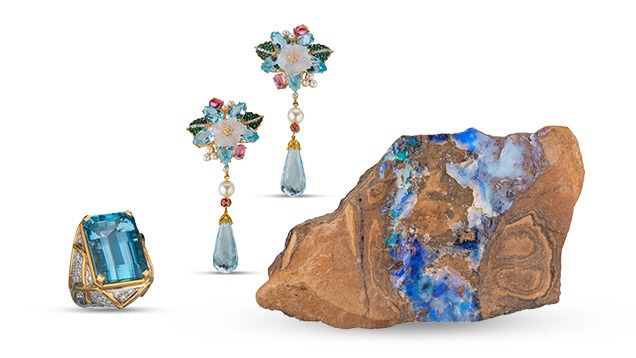

engagement_ring_settings_guide.pdf - page 1 - xref 6 - 1440×810 - jpeg


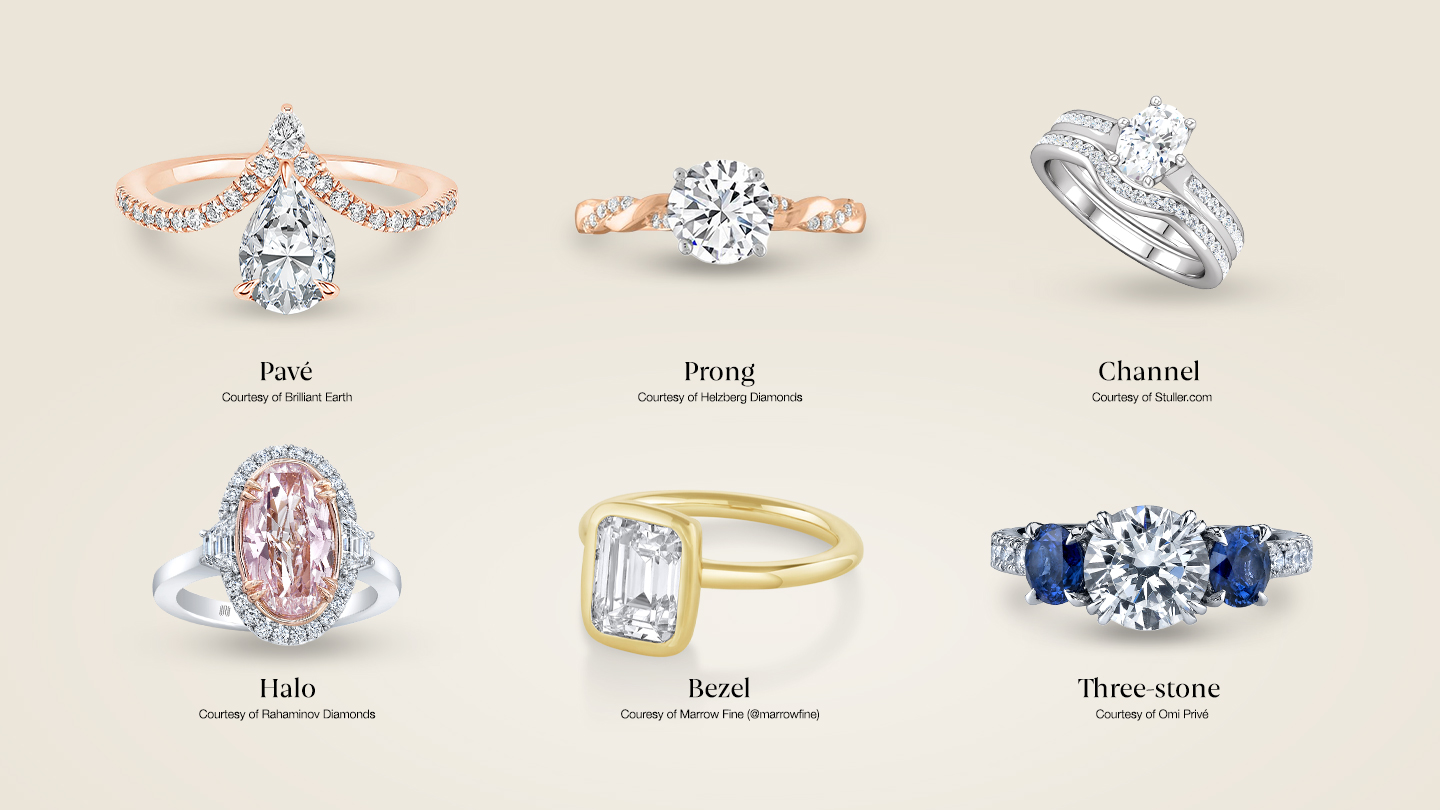

alexandrite.pdf - page 1 - xref 72 - 549×416 - jpeg


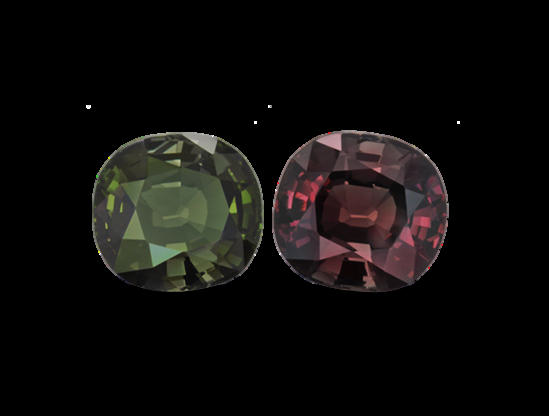

amber.pdf - page 1 - xref 76 - 549×416 - jpeg


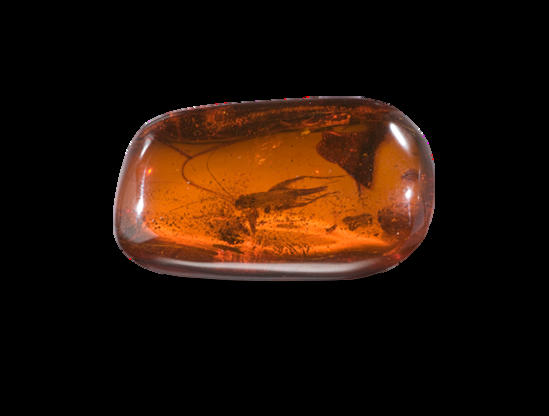

amethyst.pdf - page 1 - xref 79 - 550×416 - jpeg


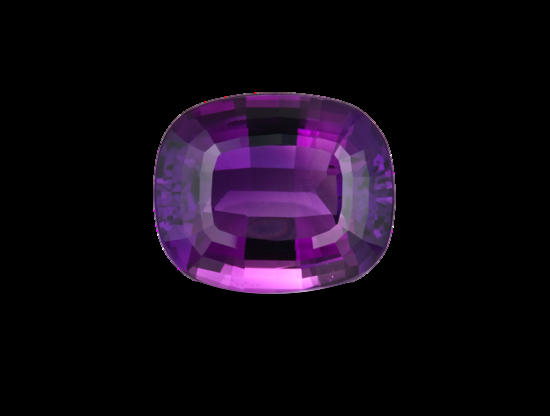

ametrine.pdf - page 1 - xref 78 - 552×416 - jpeg


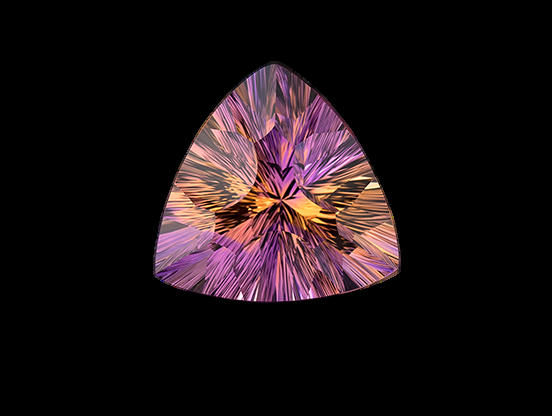

aquamarine.pdf - page 1 - xref 79 - 550×416 - jpeg


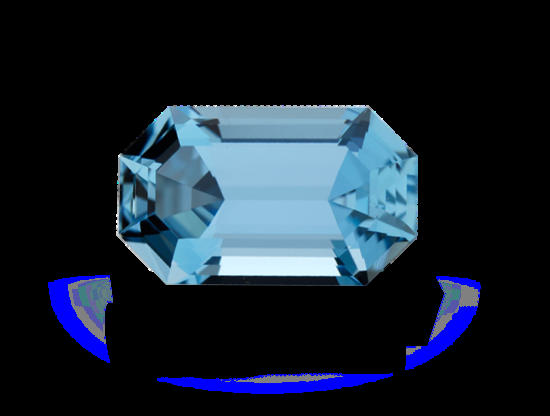

citrine.pdf - page 1 - xref 79 - 552×416 - jpeg


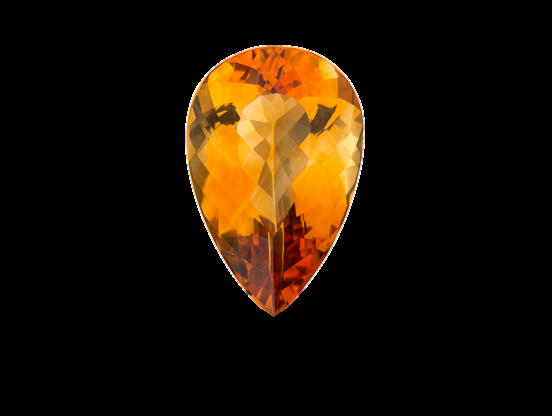

Displayed 8 sample image(s).


In [6]:
SAMPLE_PER_PDF = 1
MAX_SAMPLES = 8

displayed_images = set()
shown = 0

for pdf_file in PDF_FILES:
    if shown >= MAX_SAMPLES:
        break

    per_pdf = 0
    for row in selected_image_rows:
        if row["file_name"] != pdf_file.name:
            continue
        xref = row["xref"]
        image_key = (row["source_path"], xref)
        if xref <= 0 or image_key in displayed_images:
            continue

        displayed_images.add(image_key)
        extracted = extract_pdf_image(row["source_path"], xref)
        print(
            f"{row['file_name']} - page {row['page_number']} - "
            f"xref {xref} - {extracted['width']}×{extracted['height']} - "
            f"{extracted['extension']}"
        )
        display(Image(data=extracted["image_bytes"]))

        per_pdf += 1
        shown += 1
        if per_pdf >= SAMPLE_PER_PDF or shown >= MAX_SAMPLES:
            break

print(f"Displayed {shown} sample image(s).")


# 4. Image split across PDF pages

Check whether images continue from one page onto the next in a multi page jewelry PDF.


In [7]:
split_image_records = [
    record
    for document in document_image_inspections
    for record in find_split_image_placements(document)
]
split_image_summary = pd.DataFrame([
    {
        "file_name": record["file_name"],
        "digest": record["digest"],
        "page_numbers": record["page_numbers"],
        "placements": len(record["placements"]),
    }
    for record in split_image_records
])
print("Images detected across adjacent page boundaries:", len(split_image_records))
display(split_image_summary if len(split_image_summary) else pd.DataFrame({"result": ["No matching image digest touches adjacent page edges"]}))

Images detected across adjacent page boundaries: 0


,result
0,No matching image digest touches adjacent page...


In [8]:
if split_image_records:
    split_record = split_image_records[0]
    print("Example:", split_record["file_name"], "pages:", split_record["page_numbers"])
    display(pd.DataFrame(split_record["placements"])[[
        "page_number", "image_index", "xref", "bbox", "visible_fraction", "touches_top", "touches_bottom"
    ]])
    seen_xrefs = set()
    for placement in split_record["placements"]:
        xref = placement["xref"]
        key = (placement["source_path"], xref)
        if xref <= 0 or key in seen_xrefs:
            continue
        seen_xrefs.add(key)
        extracted = extract_pdf_image(placement["source_path"], xref)
        print(f"xref {xref} | {extracted['width']}x{extracted['height']} | {extracted['extension']}")
        display(Image(data=extracted["image_bytes"]))
else:
    print("No cross-page image was detected in the inspected PDFs.")

No cross-page image was detected in the inspected PDFs.
